# Out-of-distribution (OOS) experiments

In [12]:
# Imports and setup

import torch
import os
import numpy as np

from experiments_helper import (
    LOG_DIR,
    create_log_dir,
    create_fig_dir,
    save_results,
    load_results,
    run_experiment_suite,
    compute_loss_dict,
    compute_looped_loss_by_loop_count,
    compute_dist_dict,
    plot_loss_curves,
    plot_dist_to_identity,
    plot_loop_loss_curves,
    # Problem parameters (edit them in experiments_helper.py)
    device, N, d, n_head,
    max_iters, hist_stride, stride, TEST_SEED,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

create_log_dir()
print(f'Running on device: {device}.')

In [ ]:
# Loader for the results this notebook saves. Returns the saved dictionary.

def load_oos_results():
    """Load the saved identity-train / adjusted-test results."""
    return load_results(os.path.join(
        LOG_DIR, f'identity_train_adjusted_test_N{N}_d{d}_results.pth'))

In [ ]:
# Restore saved results into the same variables the training cell creates,
# so the evaluation and plotting cells can run without retraining.

def restore_oos_results():
    global oos_hist_dict, oos_loss_dict, oos_dist_dict, U_test, D_test
    global oos_seeds, oos_counts, oos_model_types, oos_iterations, oos_fig_dir

    results = load_oos_results()
    oos_hist_dict = results['hist_dict']
    oos_loss_dict = results['loss_dict']
    oos_dist_dict = results['distance_dict']
    U_test = results['U_test'].to(device)
    D_test = results['D_test'].to(device)
    oos_seeds = results['seeds']
    oos_counts = results['counts']
    oos_model_types = results['model_types']

    oos_iterations = np.arange(0, max_iters, stride)
    oos_fig_dir = create_fig_dir('oos_regular')

    print(f'Restored {len(oos_hist_dict)} runs')

In [15]:
# Train on the notebook's standard identity-covariance data, then evaluate on
# the adjusted (rotated and rescaled) covariate distribution.
# Reuse run_experiment_suite, compute_loss_dict, and compute_dist_dict.

oos_seeds = [0, 1, 2]
oos_counts = [2, 5]
oos_model_types = ['looped']
oos_fig_dir = create_fig_dir('oos_regular')
oos_filename = os.path.join(LOG_DIR, 'oos_regular.pth')

# Fixed test-time covariance Sigma = U D^2 U^T; training remains unchanged
# and uses generate_data without U,D, i.e. identity covariance.
if d != 5:
    raise ValueError('This covariance setup is defined for d=5.')
torch.manual_seed(1234)
rotation_seed_matrix = (2 * torch.rand(d, d, device=device)) - 1
U_test = torch.linalg.svd(rotation_seed_matrix, full_matrices=True).U
D_test = torch.diag(torch.tensor([1, 1, 0.5, 0.25, 1], device=device))

# Train 2/5-loop transformers with the existing training routine.
oos_hist_dict = run_experiment_suite(
    oos_seeds,
    oos_counts,
    oos_model_types,
    oos_filename,
    context_lengths=[N],
    freeze_p=True,  # [P-FIX] paper's P = [[0, 0], [0, 1]]
)

# Compute test loss versus training iteration and parameter distances before plotting.
oos_loss_dict = compute_loss_dict(
    oos_hist_dict,
    U=U_test,
    D=D_test,
    test_seed=TEST_SEED,
)
oos_iterations = np.arange(0, max_iters, stride)
oos_dist_dict = compute_dist_dict(
    oos_hist_dict,
    oos_iterations,
    n_head,
    hist_stride=hist_stride,
)

save_results(
    {
        'hist_dict': oos_hist_dict,
        'loss_dict': oos_loss_dict,
        'distance_dict': oos_dist_dict,
        'U_test': U_test.detach().cpu(),
        'D_test': D_test.detach().cpu(),
        'seeds': oos_seeds,
        'counts': oos_counts,
        'model_types': oos_model_types,
        'context_length': N,
    },
    os.path.join(LOG_DIR, f'identity_train_adjusted_test_N{N}_d{d}_results.pth'),
)

Run 1/6: seed=0, count=2, type=looped, N=20, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear, freeze_p=True, learn_u=False
iter 0 | Loss: 5.274796962738037 | time: 0.0067408084869384766 | gradnorm: 9.615306854248047
iter 1 | Loss: 5.0525431632995605 | time: 0.006335735321044922 | gradnorm: 9.10390567779541
iter 2 | Loss: 4.928557395935059 | time: 0.006143331527709961 | gradnorm: 8.7908296585083
iter 3 | Loss: 4.843500137329102 | time: 0.006114482879638672 | gradnorm: 8.58931827545166
iter 4 | Loss: 5.005734443664551 | time: 0.00610041618347168 | gradnorm: 9.079337120056152
iter 100 | Loss: 3.3704450130462646 | time: 0.005231142044067383 | gradnorm: 6.131927490234375
iter 200 | Loss: 2.2515196800231934 | time: 0.00521397590637207 | gradnorm: 3.968468189239502
iter 300 | Loss: 1.5689407587051392 | time: 0.005068302154541016 | gradnorm: 2.5794482231140137
iter 400 | Loss: 1.1575946807861328 | time: 0.005178928375244141 | 

In [ ]:
# Load the saved adjusted-distribution results instead of retraining
# (skip the training cell above).
restore_oos_results()

In [16]:
# Evaluate final looped checkpoints with 1 through 50 inference loops.
oos_looped_hist_dict = {
    key: history
    for key, history in oos_hist_dict.items()
    if key[2] == 'looped'
}

oos_loop_loss_dict = compute_looped_loss_by_loop_count(
    oos_looped_hist_dict,
    max_loops=50,
    U=U_test,
    D=D_test,
    test_seed=TEST_SEED,
)

Testing: (0, 2, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Evaluated checkpoint (0, 2, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1) through 50 loops.
Testing: (0, 5, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Evaluated checkpoint (0, 5, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1) through 50 loops.
Testing: (1, 2, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Evaluated checkpoint (1, 2, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1) through 50 loops.
Testing: (1, 5, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Evaluated checkpoint (1, 5, 'looped', 20, DataMode(name='normal', gamma_shape=None, 

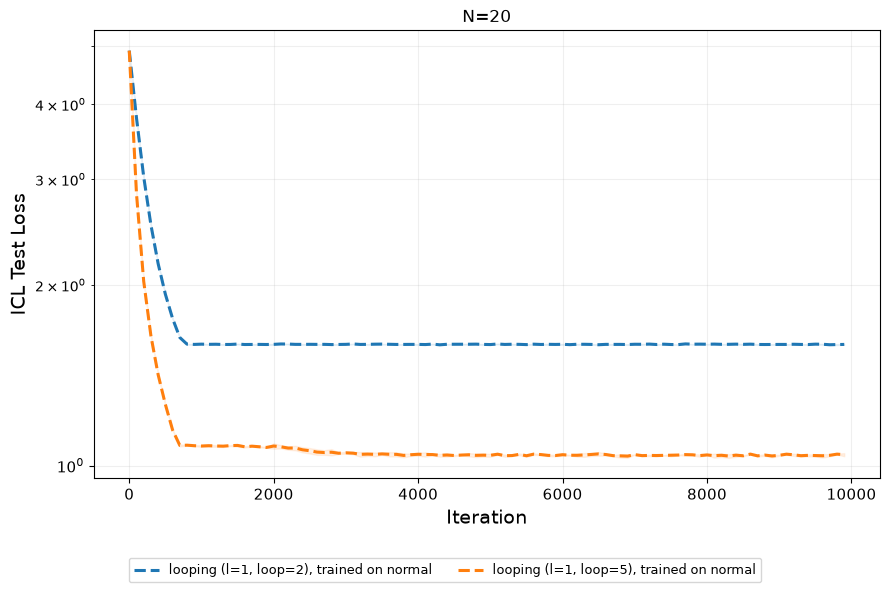

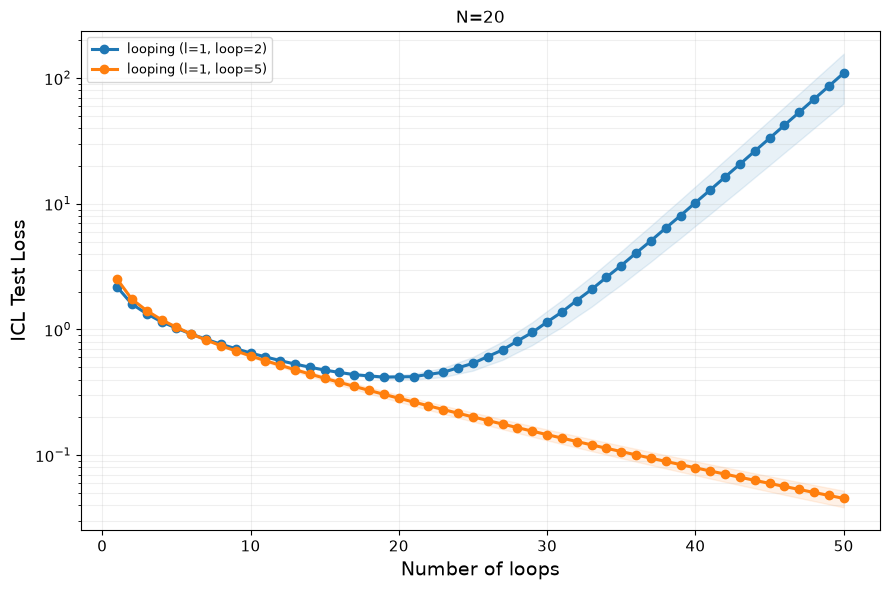

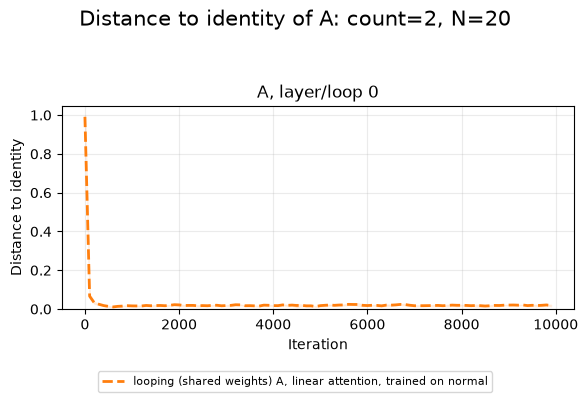

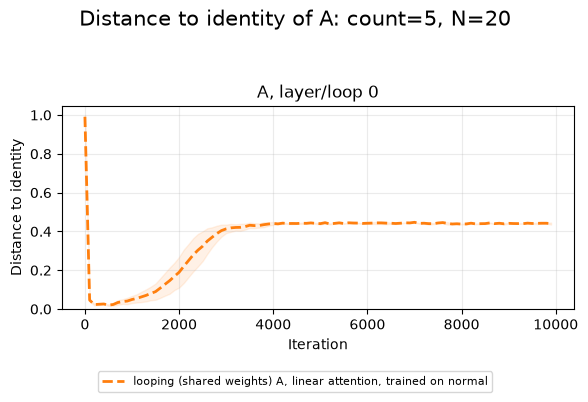

In [17]:
# Plot the adjusted-distribution test loss by training iteration.
plot_loss_curves(
    oos_loss_dict,
    oos_counts,
    oos_model_types,
    oos_iterations,
    fig_dir=oos_fig_dir,
    filename='adjusted_distribution_test_loss.pdf',
)

# Plot looped-model test loss against the number of inference loops (1..50).
plot_loop_loss_curves(
    oos_loop_loss_dict,
    n_layers_loops=oos_counts,
    loop_counts=range(1, 51),
    fig_dir=oos_fig_dir,
    filename='adjusted_distribution_loss_vs_loop_count.pdf',
)

# Plot distance-to-identity for the trained looped-model parameters.
plot_dist_to_identity(
    oos_dist_dict,
    oos_counts,
    oos_iterations,
    fig_dir=oos_fig_dir,
)

Testing: (0, 2, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Evaluated checkpoint (0, 2, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1) through 500 loops.
Testing: (0, 5, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Evaluated checkpoint (0, 5, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1) through 500 loops.
Testing: (1, 2, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Evaluated checkpoint (1, 2, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1) through 500 loops.
Testing: (1, 5, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Evaluated checkpoint (1, 5, 'looped', 20, DataMode(name='normal', gamma_shape=Non

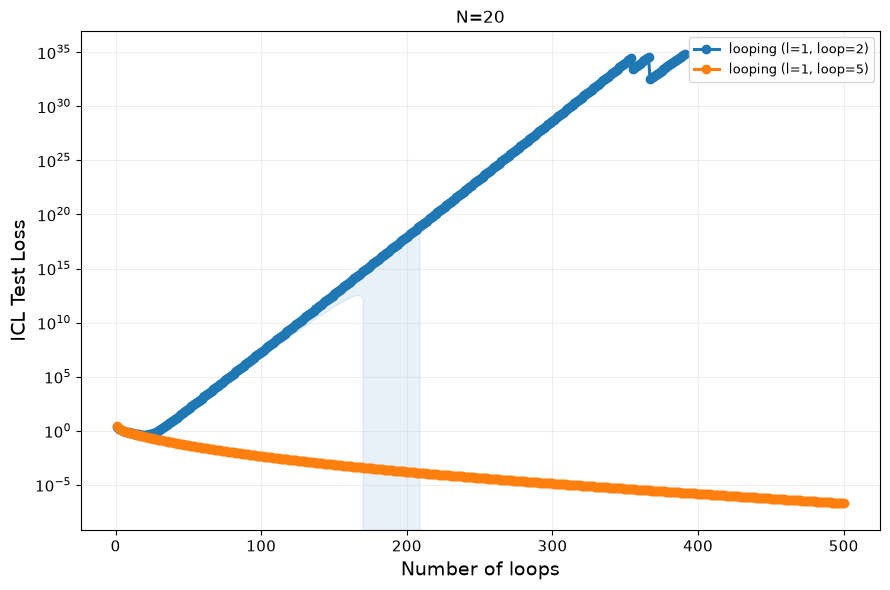

In [18]:
# Sensitivity test: Let's try very large max loop values
oos_loop_loss_dict = compute_looped_loss_by_loop_count(
    oos_looped_hist_dict,
    max_loops=500,
    U=U_test,
    D=D_test,
    test_seed=TEST_SEED,
)

# Plot looped-model test loss against the number of inference loops (1..501).
plot_loop_loss_curves(
    oos_loop_loss_dict,
    n_layers_loops=oos_counts,
    loop_counts=range(1, 501),
    fig_dir=oos_fig_dir,
    filename='adjusted_distribution_loss_vs_extended_loop_count.pdf',
)